Вопрос 1: Влияет ли загруженность аэропорта на задержки рейсов(Гипотеза: с увеличением количества рейсов в час доля задержек возрастает, в связи с нагрузкой на инфраструктуру аэропорта)

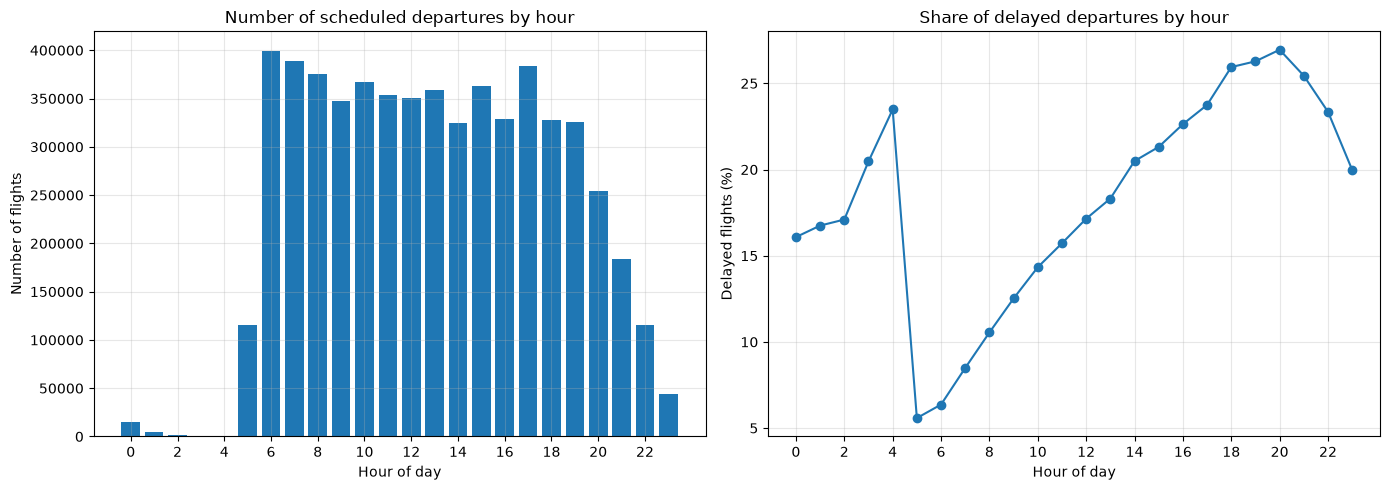

            FLIGHTS  DELAYED_COUNT  DELAY_RATE
LOAD_GROUP                                    
1-5         1259233         191215   15.185037
6-10         783767         132479   16.902855
11-20       1204016         230653   19.156971
21-30        936700         172620   18.428526
31-50        868535         160545   18.484575
51-100       673369         128248   19.045724
>100           3575            776   21.706294


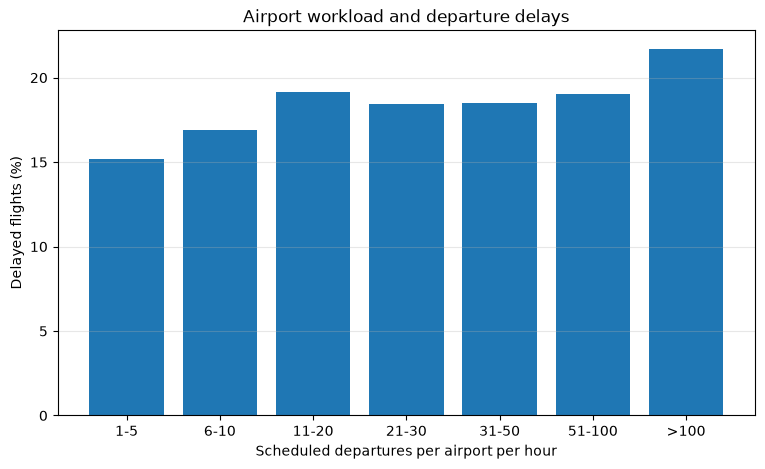

In [19]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

path = kagglehub.dataset_download("usdot/flight-delays")

flights = pd.read_csv(
    os.path.join(path, "flights.csv"),
    usecols=[
        "YEAR", "MONTH", "DAY",
        "ORIGIN_AIRPORT", "SCHEDULED_DEPARTURE",
        "DEPARTURE_DELAY", "CANCELLED"
    ],
    dtype={"ORIGIN_AIRPORT": "string"}
)

flights = flights[
    (flights["CANCELLED"] == 0) &
    (flights["DEPARTURE_DELAY"].notna()) &
    (flights["SCHEDULED_DEPARTURE"].notna())
].copy()

flights["HOUR"] = (
    flights["SCHEDULED_DEPARTURE"] // 100
).astype(int) % 24

flights["DELAYED"] = flights["DEPARTURE_DELAY"] > 15

hourly = flights.groupby("HOUR").agg(
    FLIGHTS=("DELAYED", "size"),
    DELAY_RATE=("DELAYED", "mean")
).reindex(range(24), fill_value=0)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].bar(hourly.index, hourly["FLIGHTS"])
ax[0].set_title("Number of scheduled departures by hour")
ax[0].set_xlabel("Hour of day")
ax[0].set_ylabel("Number of flights")

ax[1].plot(
    hourly.index,
    hourly["DELAY_RATE"] * 100,
    marker="o"
)
ax[1].set_title("Share of delayed departures by hour")
ax[1].set_xlabel("Hour of day")
ax[1].set_ylabel("Delayed flights (%)")

for a in ax:
    a.set_xticks(range(0, 24, 2))
    a.grid(alpha=0.3)

plt.tight_layout()
plt.show()

load = flights.groupby(
    ["ORIGIN_AIRPORT", "YEAR", "MONTH", "DAY", "HOUR"]
).agg(
    FLIGHTS=("DELAYED", "size"),
    DELAYED_COUNT=("DELAYED", "sum")
).reset_index()

bins = [0, 5, 10, 20, 30, 50, 100, np.inf]
labels = ["1-5", "6-10", "11-20", "21-30",
          "31-50", "51-100", ">100"]

load["LOAD_GROUP"] = pd.cut(
    load["FLIGHTS"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

result = load.groupby(
    "LOAD_GROUP", observed=True
)[["FLIGHTS", "DELAYED_COUNT"]].sum()

result["DELAY_RATE"] = (
    result["DELAYED_COUNT"] / result["FLIGHTS"] * 100
)

print(result)

plt.figure(figsize=(9, 5))
plt.bar(result.index.astype(str), result["DELAY_RATE"])

plt.xlabel("Scheduled departures per airport per hour")
plt.ylabel("Delayed flights (%)")
plt.title("Airport workload and departure delays")
plt.grid(axis="y", alpha=0.3)

plt.show()


Вывод: Анализ показал, что загруженность аэропортов связана с частотой задержек: при интенсивности 1–5 рейсов в час доля задержек составляет 15,18%, а при более 100 рейсах — 21,71%.

При этом максимальная доля задержек (26–27%) наблюдается вечером, несмотря на снижение числа вылетов. Это может свидетельствовать о накоплении задержек в течение дня.

Гипотеза 2: Задержка прибытия самолёта увеличивает вероятность задержки его следующего вылета, вызывая последовательное распространение задержек между рейсами. Причем величина задержки может увеличиваться от рейса к рейсу в течении дня

Количество сопоставленных пар рейсов: 4292487
Среднее изменение задержки: 7.7 мин
Медианное изменение задержки: 5.0 мин
Доля пар с увеличением задержки: 67.07 %


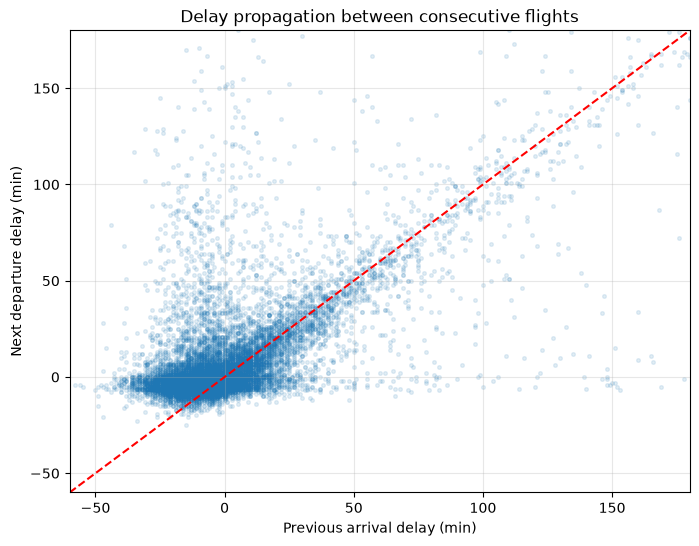

                   mean  median    count
PREV_DELAY_GROUP                        
<=0               13.41     9.0  2815680
0-15               1.59    -3.0   804173
15-30             -1.25    -5.0   276246
30-60             -4.15    -5.0   208895
60-120           -11.97    -7.0   126820
>120             -53.74   -12.0    60673


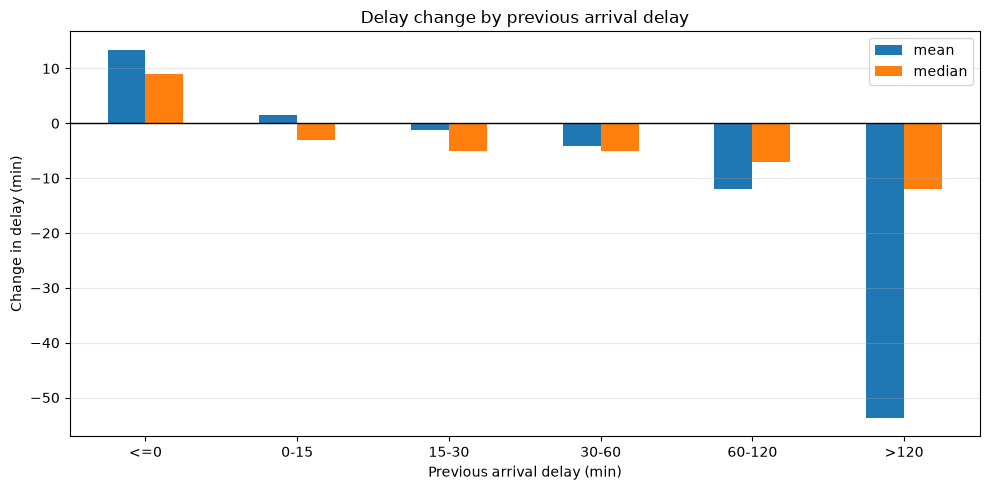

            mean  median    count
LEG_NUMBER                       
2           8.67     7.0  1219343
3           8.04     5.0  1053752
4           8.40     6.0   847628
5           6.71     4.0   561077
6           6.27     4.0   357225
7           4.25     2.0   144399
8           3.52     2.0    73108


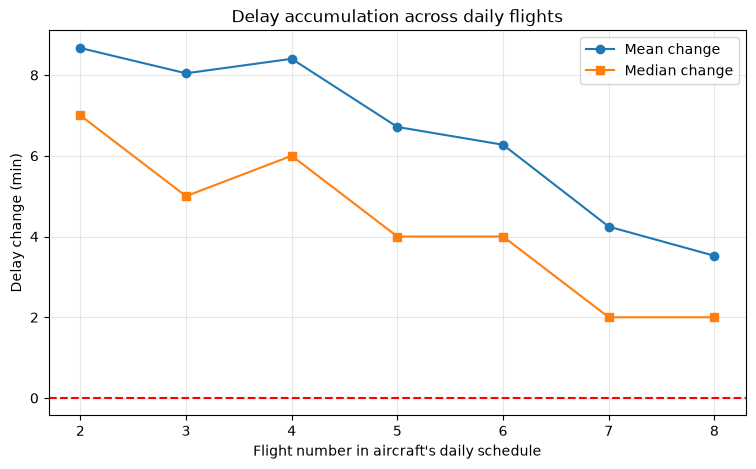

In [18]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

path = kagglehub.dataset_download("usdot/flight-delays")

flights = pd.read_csv(
    os.path.join(path, "flights.csv"),
    usecols=[
        "YEAR", "MONTH", "DAY", "TAIL_NUMBER",
        "ORIGIN_AIRPORT", "DESTINATION_AIRPORT",
        "SCHEDULED_DEPARTURE", "DEPARTURE_DELAY",
        "ARRIVAL_DELAY", "CANCELLED", "DIVERTED"
    ],
    dtype={
        "TAIL_NUMBER": "string",
        "ORIGIN_AIRPORT": "string",
        "DESTINATION_AIRPORT": "string"
    }
)

flights["DATE"] = pd.to_datetime(
    flights[["YEAR", "MONTH", "DAY"]]
)

flights = flights.dropna(
    subset=["TAIL_NUMBER", "SCHEDULED_DEPARTURE"]
).copy()

flights = flights.sort_values(
    ["TAIL_NUMBER", "DATE", "SCHEDULED_DEPARTURE"]
)

group = flights.groupby(["TAIL_NUMBER", "DATE"])

flights["LEG_NUMBER"] = group.cumcount() + 1
flights["PREV_ARRIVAL_DELAY"] = group["ARRIVAL_DELAY"].shift(1)
flights["PREV_DESTINATION"] = group["DESTINATION_AIRPORT"].shift(1)
flights["PREV_CANCELLED"] = group["CANCELLED"].shift(1)
flights["PREV_DIVERTED"] = group["DIVERTED"].shift(1)

data = flights[
    (flights["CANCELLED"] == 0) &
    (flights["DIVERTED"] == 0) &
    (flights["PREV_CANCELLED"] == 0) &
    (flights["PREV_DIVERTED"] == 0) &
    (flights["ORIGIN_AIRPORT"] == flights["PREV_DESTINATION"]) &
    flights["DEPARTURE_DELAY"].notna() &
    flights["PREV_ARRIVAL_DELAY"].notna()
].copy()

data["DELAY_CHANGE"] = (
    data["DEPARTURE_DELAY"] - data["PREV_ARRIVAL_DELAY"]
)

print("Количество сопоставленных пар рейсов:", len(data))
print("Среднее изменение задержки:",
      round(data["DELAY_CHANGE"].mean(), 2), "мин")
print("Медианное изменение задержки:",
      round(data["DELAY_CHANGE"].median(), 2), "мин")

print("Доля пар с увеличением задержки:",
      round(100 * (data["DELAY_CHANGE"] > 0).mean(), 2), "%")

sample = data.sample(n=min(15000, len(data)), random_state=42)

plt.figure(figsize=(8, 6))
plt.scatter(
    sample["PREV_ARRIVAL_DELAY"],
    sample["DEPARTURE_DELAY"],
    alpha=0.12, s=7
)

plt.plot([-60, 180], [-60, 180], color="red", linestyle="--")
plt.xlim(-60, 180)
plt.ylim(-60, 180)
plt.xlabel("Previous arrival delay (min)")
plt.ylabel("Next departure delay (min)")
plt.title("Delay propagation between consecutive flights")
plt.grid(alpha=0.3)
plt.show()

bins = [-np.inf, 0, 15, 30, 60, 120, np.inf]
labels = ["<=0", "0-15", "15-30", "30-60", "60-120", ">120"]

data["PREV_DELAY_GROUP"] = pd.cut(
    data["PREV_ARRIVAL_DELAY"],
    bins=bins,
    labels=labels
)

delay_groups = data.groupby(
    "PREV_DELAY_GROUP", observed=True
)["DELAY_CHANGE"].agg(["mean", "median", "count"])

print(delay_groups.round(2))

delay_groups[["mean", "median"]].plot(
    kind="bar", figsize=(10, 5)
)

plt.axhline(0, color="black", linewidth=1)
plt.xlabel("Previous arrival delay (min)")
plt.ylabel("Change in delay (min)")
plt.title("Delay change by previous arrival delay")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

by_leg = data[data["LEG_NUMBER"].between(2, 8)].groupby(
    "LEG_NUMBER"
)["DELAY_CHANGE"].agg(["mean", "median", "count"])

print(by_leg.round(2))

plt.figure(figsize=(9, 5))
plt.plot(by_leg.index, by_leg["mean"], marker="o",
         label="Mean change")
plt.plot(by_leg.index, by_leg["median"], marker="s",
         label="Median change")

plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Flight number in aircraft's daily schedule")
plt.ylabel("Delay change (min)")
plt.title("Delay accumulation across daily flights")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


Вывод: в 67,07% случаев задержка следующего вылета превышает задержку предыдущего прибытия. Среднее увеличение составляет 7,7 минуты, медианное 5 минут.

Однако при значительных опозданиях наблюдается обратная тенденция: если предыдущий рейс задержался на 30-60 минут, следующая задержка в среднем сокращается на 4,15 минуты, а при опоздании более 120 минут на 53,74 минуты.

Кроме того, среднее изменение задержки снижается с 8,67 минуты на втором рейсе за день до 3,52 минуты на восьмом. То есть гипотеза о последовательном усилении задержек в течение дня не подтвердилась.Хотя задержки часто увеличиваются между рейсами, при крупных опозданиях наблюдается их частичная компенсация, а средний прирост задержки уменьшается с увеличением порядкового номера рейса.



Гипотеза 3: неблагоприятные погодные условия являются одним из основных факторов задержек авиарейсов, причём их влияние существенно различается между сезонами и аэропортами.

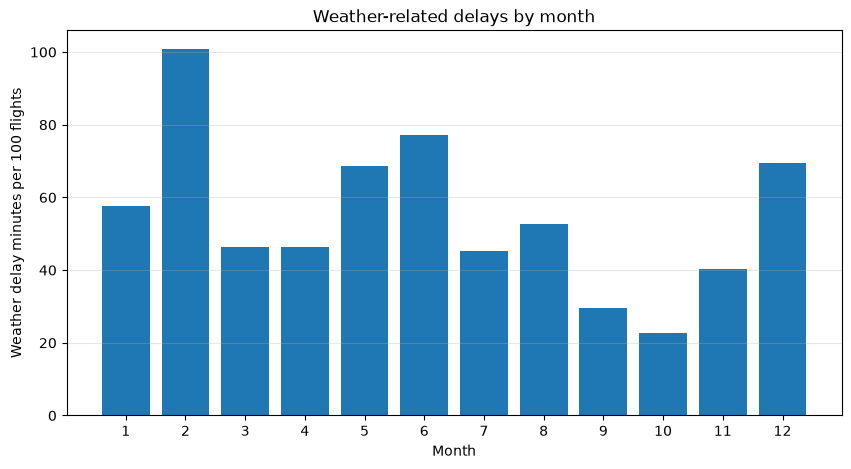

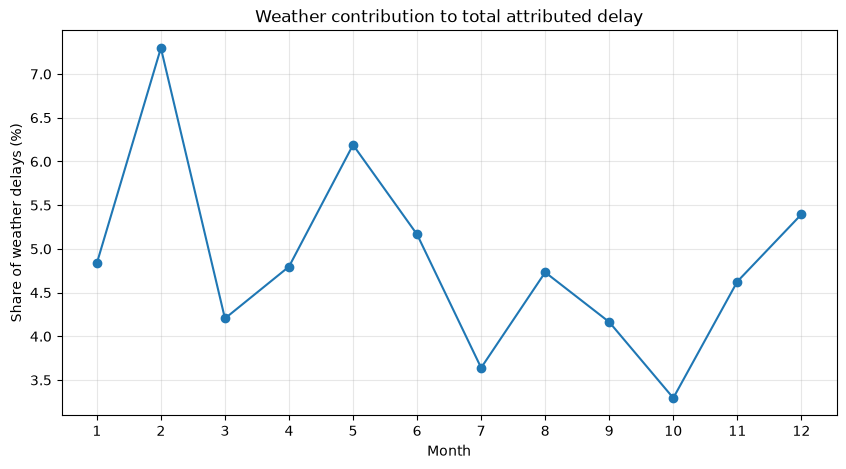

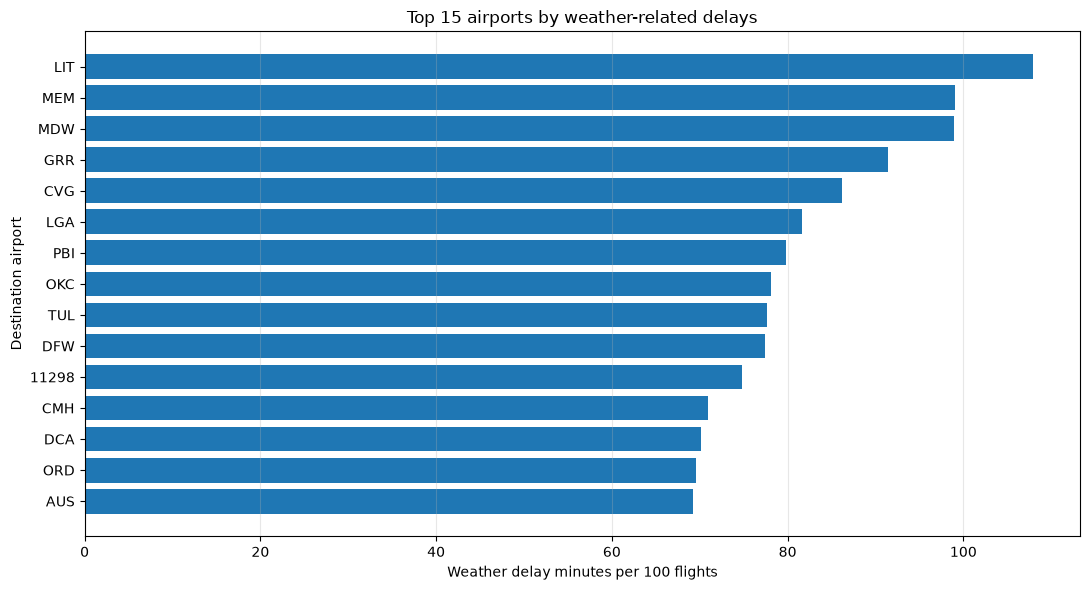

Доля погодных задержек в общем времени задержек:
4.95 %

Погодные задержки по месяцам:
       FLIGHTS  WEATHER_MINUTES  TOTAL_MINUTES  WEATHER_PER_100  WEATHER_SHARE
MONTH                                                                         
1       457013         263087.0      5439862.0            57.57           4.84
2       407663         411265.0      5635596.0           100.88           7.30
3       492138         228661.0      5438910.0            46.46           4.20
4       479251         221590.0      4619308.0            46.24           4.80
5       489641         336555.0      5437359.0            68.74           6.19
6       492847         380699.0      7370820.0            77.24           5.16
7       514384         232468.0      6386504.0            45.19           3.64
8       503956         265792.0      5616471.0            52.74           4.73
9       462153         137043.0      3291587.0            29.65           4.16
10      482878         109225.0      3315230

In [17]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

path = kagglehub.dataset_download("usdot/flight-delays")

flights = pd.read_csv(
    os.path.join(path, "flights.csv"),
    usecols=[
        "MONTH", "DESTINATION_AIRPORT",
        "WEATHER_DELAY", "AIRLINE_DELAY",
        "AIR_SYSTEM_DELAY", "SECURITY_DELAY",
        "LATE_AIRCRAFT_DELAY", "CANCELLED", "DIVERTED"
    ],
    dtype={"DESTINATION_AIRPORT": "string"}
)

flights = flights[
    (flights["CANCELLED"] == 0) &
    (flights["DIVERTED"] == 0)
].copy()

delay_columns = [
    "WEATHER_DELAY", "AIRLINE_DELAY",
    "AIR_SYSTEM_DELAY", "SECURITY_DELAY",
    "LATE_AIRCRAFT_DELAY"
]

flights[delay_columns] = flights[delay_columns].fillna(0)
flights["TOTAL_DELAY"] = flights[delay_columns].sum(axis=1)

monthly = flights.groupby("MONTH").agg(
    FLIGHTS=("WEATHER_DELAY", "size"),
    WEATHER_MINUTES=("WEATHER_DELAY", "sum"),
    TOTAL_MINUTES=("TOTAL_DELAY", "sum")
)

monthly["WEATHER_PER_100"] = (
    monthly["WEATHER_MINUTES"] / monthly["FLIGHTS"] * 100
)

monthly["WEATHER_SHARE"] = (
    monthly["WEATHER_MINUTES"] /
    monthly["TOTAL_MINUTES"].replace(0, np.nan) * 100
)

plt.figure(figsize=(10, 5))
plt.bar(monthly.index, monthly["WEATHER_PER_100"])
plt.xlabel("Month")
plt.ylabel("Weather delay minutes per 100 flights")
plt.title("Weather-related delays by month")
plt.xticks(range(1, 13))
plt.grid(axis="y", alpha=0.3)
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(monthly.index, monthly["WEATHER_SHARE"], marker="o")
plt.xlabel("Month")
plt.ylabel("Share of weather delays (%)")
plt.title("Weather contribution to total attributed delay")
plt.xticks(range(1, 13))
plt.grid(alpha=0.3)
plt.show()

airports = flights.groupby("DESTINATION_AIRPORT").agg(
    FLIGHTS=("WEATHER_DELAY", "size"),
    WEATHER_MINUTES=("WEATHER_DELAY", "sum")
)

airports = airports[airports["FLIGHTS"] >= 10000].copy()

airports["WEATHER_PER_100"] = (
    airports["WEATHER_MINUTES"] / airports["FLIGHTS"] * 100
)

top_airports = airports.nlargest(15, "WEATHER_PER_100")

plt.figure(figsize=(11, 6))
plt.barh(
    top_airports.index.astype(str)[::-1],
    top_airports["WEATHER_PER_100"][::-1]
)
plt.xlabel("Weather delay minutes per 100 flights")
plt.ylabel("Destination airport")
plt.title("Top 15 airports by weather-related delays")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

total_weather = flights["WEATHER_DELAY"].sum()
total_delay = flights["TOTAL_DELAY"].sum()

print("Доля погодных задержек в общем времени задержек:")
print(round(total_weather / total_delay * 100, 2), "%")

print("\nПогодные задержки по месяцам:")
print(monthly.round(2))

print("\nТоп-15 аэропортов:")
print(top_airports.round(2))


Вывод: Наибольшее влияние погоды наблюдается в феврале: 100,88 минуты задержек на 100 рейсов, а наименьшее в октябре (22,62 минуты). Таким образом, показатель различается более чем в 4 раза. Среди аэропортов наиболее высокие значения наблюдаются в LIT, MEM и MDW.

При этом на погодные факторы приходится лишь 4,95% общего времени задержек с указанными причинами, поэтому гипотеза о погоде как об одном из основных факторов задержек по масштабам её прямого вклада не получила убедительного подтверждения. Однако значительные сезонные и территориальные различия подтвердились.

Гипотеза 4: вероятность задержки рейса существенно различается между авиакомпаниями, причём эти различия сохраняются даже при учёте аэропорта вылета и времени суток.

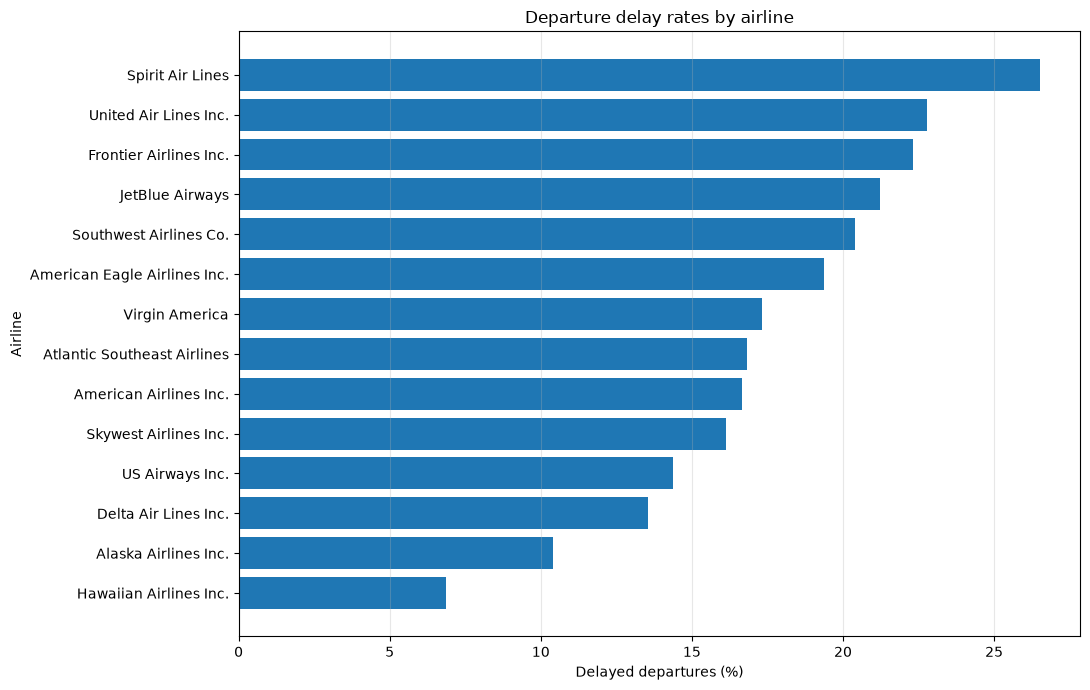

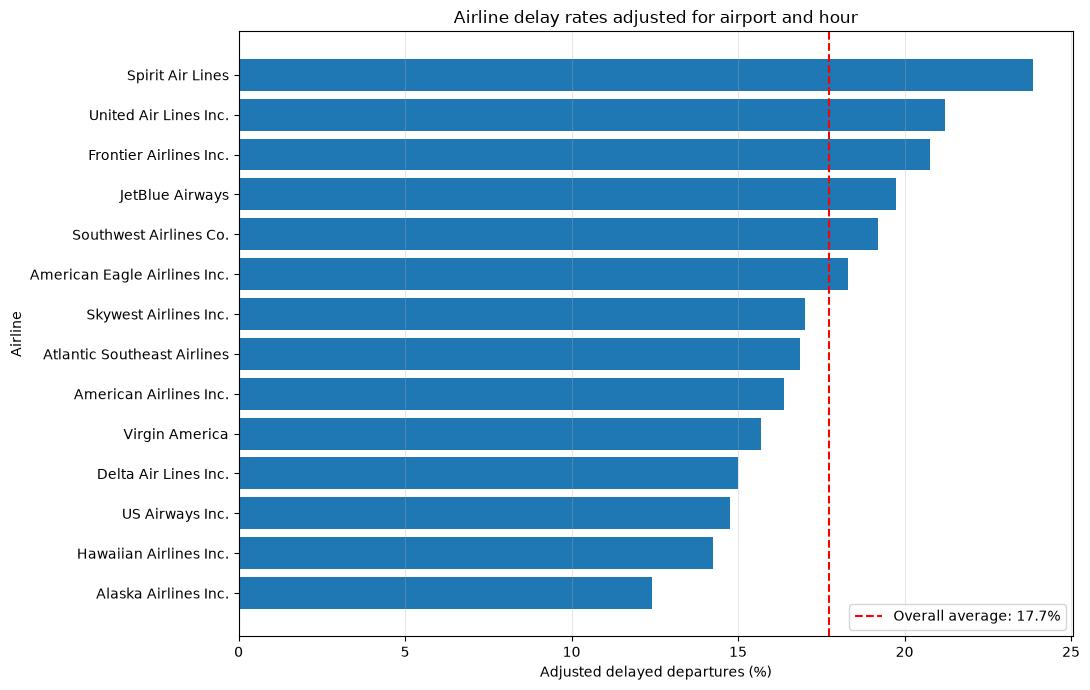

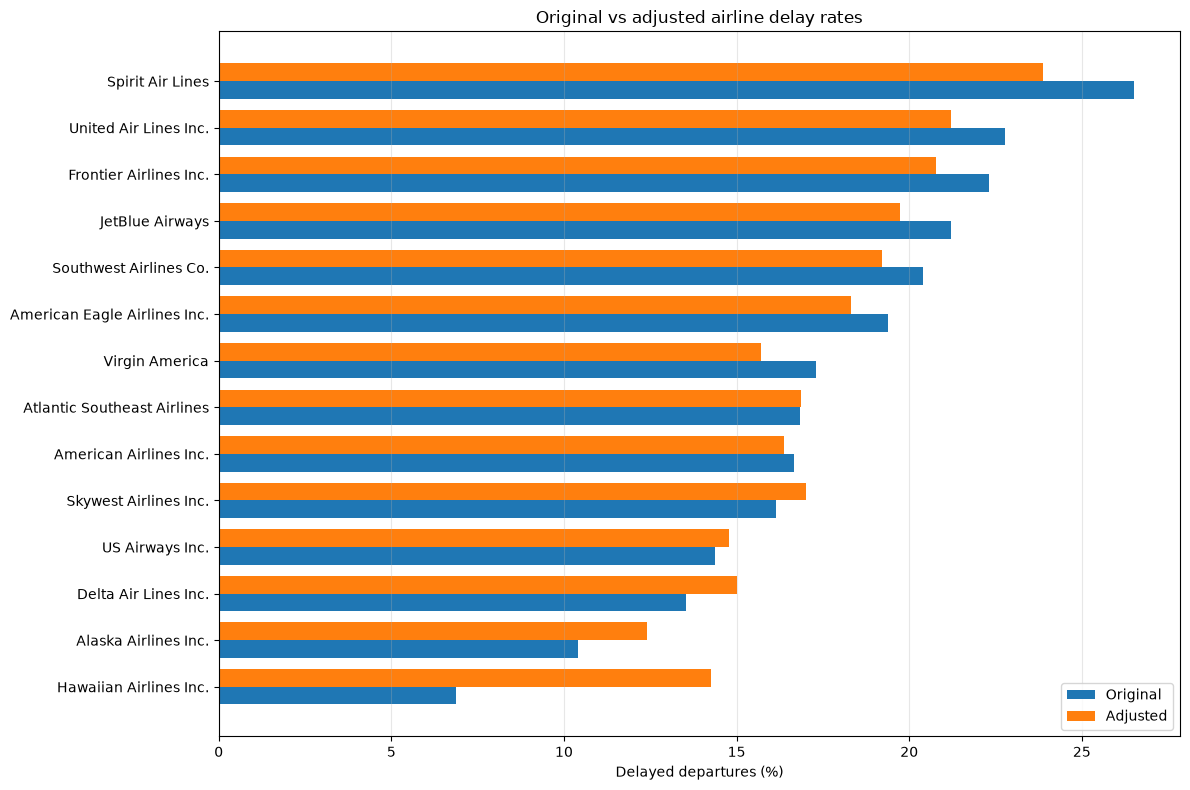

Overall delay rate: 17.74 %

Airline comparison:
                        NAME  FLIGHTS  DELAY_RATE  ADJUSTED_RATE  DIFFERENCE  AVG_DELAY
        Alaska Airlines Inc.   171852       10.42          12.41       -2.00       1.78
      Hawaiian Airlines Inc.    76101        6.87          14.25       -7.38       0.48
             US Airways Inc.   194648       14.37          14.77       -0.40       6.11
        Delta Air Lines Inc.   872057       13.54          15.00       -1.46       7.35
              Virgin America    61369       17.31          15.70        1.60       9.01
      American Airlines Inc.   715065       16.66          16.37        0.30       8.86
 Atlantic Southeast Airlines   556746       16.83          16.86       -0.03       8.66
       Skywest Airlines Inc.   578393       16.14          17.01       -0.87       7.77
American Eagle Airlines Inc.   279607       19.37          18.31        1.07      10.01
      Southwest Airlines Co.  1245812       20.39          19.22       

In [16]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

path = kagglehub.dataset_download("usdot/flight-delays")

flights = pd.read_csv(
    os.path.join(path, "flights.csv"),
    usecols=[
        "AIRLINE", "ORIGIN_AIRPORT",
        "SCHEDULED_DEPARTURE", "DEPARTURE_DELAY",
        "CANCELLED"
    ],
    dtype={"ORIGIN_AIRPORT": "string"}
)

airlines = pd.read_csv(os.path.join(path, "airlines.csv"))

flights = flights[
    (flights["CANCELLED"] == 0) &
    flights["DEPARTURE_DELAY"].notna() &
    flights["SCHEDULED_DEPARTURE"].notna()
].copy()

flights["HOUR"] = (
    flights["SCHEDULED_DEPARTURE"] // 100
).astype(int) % 24

flights["DELAYED"] = (flights["DEPARTURE_DELAY"] > 15).astype(int)

stats = flights.groupby("AIRLINE").agg(
    FLIGHTS=("DELAYED", "size"),
    DELAYED=("DELAYED", "sum"),
    AVG_DELAY=("DEPARTURE_DELAY", "mean")
)

stats["DELAY_RATE"] = stats["DELAYED"] / stats["FLIGHTS"] * 100

stats = stats.join(
    airlines.set_index("IATA_CODE")["AIRLINE"].rename("NAME")
)

stats = stats.sort_values("DELAY_RATE")

plt.figure(figsize=(11, 7))
plt.barh(stats["NAME"], stats["DELAY_RATE"])
plt.xlabel("Delayed departures (%)")
plt.ylabel("Airline")
plt.title("Departure delay rates by airline")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

reference = flights.groupby(
    ["ORIGIN_AIRPORT", "HOUR"]
)["DELAYED"].mean().rename("EXPECTED_RATE")

flights = flights.join(
    reference,
    on=["ORIGIN_AIRPORT", "HOUR"]
)

adjusted = flights.groupby("AIRLINE").agg(
    OBSERVED=("DELAYED", "sum"),
    EXPECTED=("EXPECTED_RATE", "sum")
)

overall_rate = flights["DELAYED"].mean() * 100

adjusted["ADJUSTED_RATE"] = (
    overall_rate * adjusted["OBSERVED"] / adjusted["EXPECTED"]
)

stats = stats.join(adjusted["ADJUSTED_RATE"])
stats = stats.sort_values("ADJUSTED_RATE")

plt.figure(figsize=(11, 7))
plt.barh(stats["NAME"], stats["ADJUSTED_RATE"])
plt.axvline(overall_rate, color="red", linestyle="--",
            label=f"Overall average: {overall_rate:.1f}%")
plt.xlabel("Adjusted delayed departures (%)")
plt.ylabel("Airline")
plt.title("Airline delay rates adjusted for airport and hour")
plt.legend()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

comparison = stats.sort_values("DELAY_RATE")
y = np.arange(len(comparison))
height = 0.38

plt.figure(figsize=(12, 8))

plt.barh(
    y - height / 2,
    comparison["DELAY_RATE"],
    height,
    label="Original"
)

plt.barh(
    y + height / 2,
    comparison["ADJUSTED_RATE"],
    height,
    label="Adjusted"
)

plt.yticks(y, comparison["NAME"])
plt.xlabel("Delayed departures (%)")
plt.title("Original vs adjusted airline delay rates")
plt.legend()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

stats["DIFFERENCE"] = stats["DELAY_RATE"] - stats["ADJUSTED_RATE"]

print("Overall delay rate:", round(overall_rate, 2), "%")

print("\nAirline comparison:")
print(
    stats[
        ["NAME", "FLIGHTS", "DELAY_RATE",
         "ADJUSTED_RATE", "DIFFERENCE", "AVG_DELAY"]
    ].sort_values("ADJUSTED_RATE").round(2).to_string(index=False)
)


Вывод: При общей доле задержанных рейсов 17,74% наилучшие показатели продемонстрировали Hawaiian Airlines (6,87%) и Alaska Airlines (10,42%), а наихудшие Spirit Airlines (26,52%) и United Airlines (22,76%).

После корректировки на аэропорт отправления и время суток различия сократились, но сохранились. Например, показатель Hawaiian Airlines увеличился с 6,87% до 14,25%, а Spirit Airlines снизился с 26,52% до 23,86%. Разница между ними уменьшилась с 19,65 до 9,61 процентного пункта.

Гипотеза 5: продолжительные авиарейсы реже прибывают с опозданием, поскольку имеют больше возможностей компенсировать задержку вылета во время полёта.

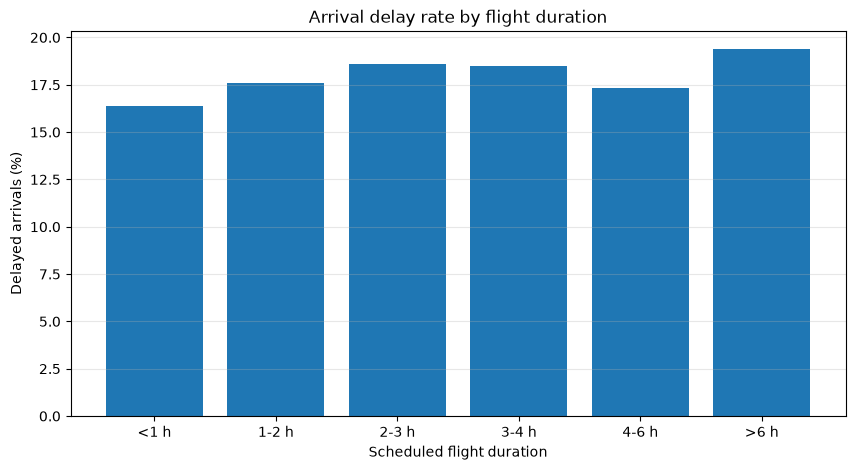

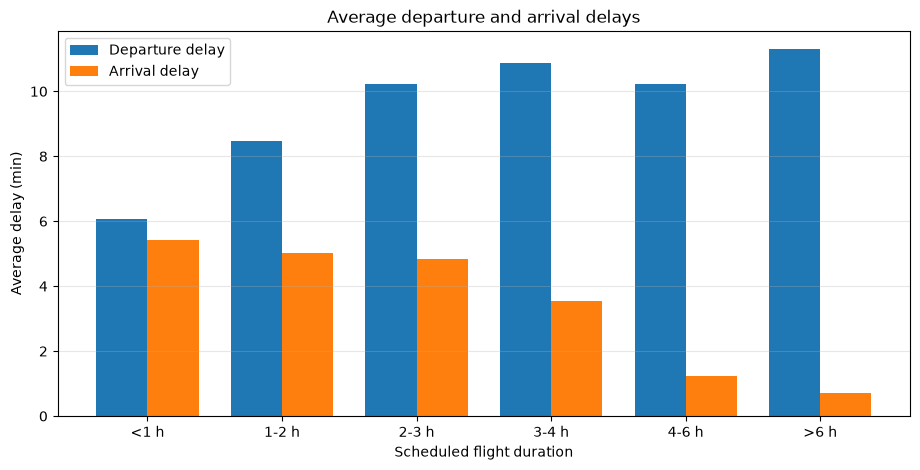

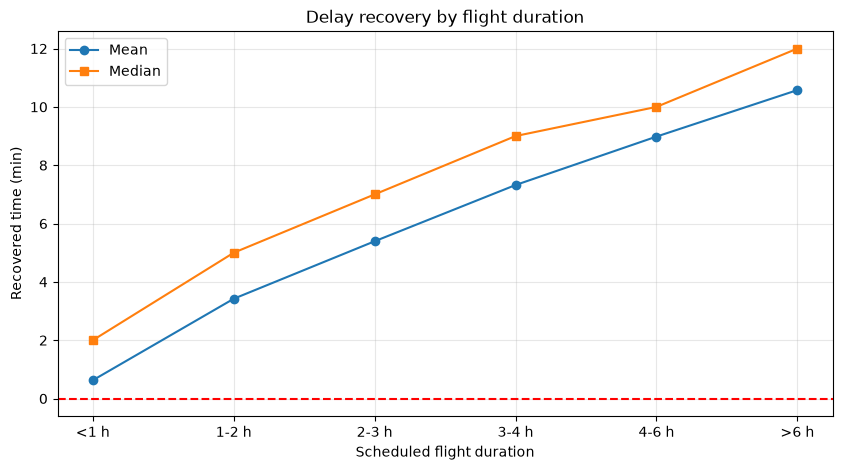

Flight duration analysis:
                FLIGHTS  DEPARTURE_RATE  ARRIVAL_RATE  AVG_DEPARTURE_DELAY  AVG_ARRIVAL_DELAY  AVG_RECOVERED  MEDIAN_RECOVERED
DURATION_GROUP                                                                                                                
<1 h             364011           14.73         16.40                 6.06               5.43           0.63               2.0
1-2 h           2436460           16.97         17.61                 8.46               5.04           3.42               5.0
2-3 h           1636297           18.62         18.57                10.22               4.83           5.39               7.0
3-4 h            647153           19.19         18.51                10.88               3.56           7.32               9.0
4-6 h            541383           18.22         17.32                10.23               1.25           8.98              10.0
>6 h              88704           19.24         19.37                11.29           

In [15]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

path = kagglehub.dataset_download("usdot/flight-delays")

flights = pd.read_csv(
    os.path.join(path, "flights.csv"),
    usecols=[
        "SCHEDULED_TIME", "AIR_TIME", "DISTANCE",
        "DEPARTURE_DELAY", "ARRIVAL_DELAY",
        "CANCELLED", "DIVERTED"
    ],
    dtype={"ORIGIN_AIRPORT": "string"}
)

flights = flights[
    (flights["CANCELLED"] == 0) &
    (flights["DIVERTED"] == 0)
].dropna(
    subset=[
        "SCHEDULED_TIME", "AIR_TIME",
        "DEPARTURE_DELAY", "ARRIVAL_DELAY"
    ]
).copy()

flights = flights[flights["SCHEDULED_TIME"] > 0].copy()

bins = [0, 60, 120, 180, 240, 360, np.inf]
labels = [
    "<1 h", "1-2 h", "2-3 h",
    "3-4 h", "4-6 h", ">6 h"
]

flights["DURATION_GROUP"] = pd.cut(
    flights["SCHEDULED_TIME"],
    bins=bins,
    labels=labels
)

flights["DEPARTURE_LATE"] = flights["DEPARTURE_DELAY"] > 15
flights["ARRIVAL_LATE"] = flights["ARRIVAL_DELAY"] > 15

flights["RECOVERED_TIME"] = (
    flights["DEPARTURE_DELAY"] - flights["ARRIVAL_DELAY"]
)

stats = flights.groupby(
    "DURATION_GROUP", observed=True
).agg(
    FLIGHTS=("ARRIVAL_LATE", "size"),
    DEPARTURE_RATE=("DEPARTURE_LATE", "mean"),
    ARRIVAL_RATE=("ARRIVAL_LATE", "mean"),
    AVG_DEPARTURE_DELAY=("DEPARTURE_DELAY", "mean"),
    AVG_ARRIVAL_DELAY=("ARRIVAL_DELAY", "mean"),
    AVG_RECOVERED=("RECOVERED_TIME", "mean"),
    MEDIAN_RECOVERED=("RECOVERED_TIME", "median")
)

stats["DEPARTURE_RATE"] *= 100
stats["ARRIVAL_RATE"] *= 100

plt.figure(figsize=(10, 5))
plt.bar(stats.index.astype(str), stats["ARRIVAL_RATE"])
plt.xlabel("Scheduled flight duration")
plt.ylabel("Delayed arrivals (%)")
plt.title("Arrival delay rate by flight duration")
plt.grid(axis="y", alpha=0.3)
plt.show()

x = np.arange(len(stats))
width = 0.38

plt.figure(figsize=(11, 5))

plt.bar(
    x - width / 2,
    stats["AVG_DEPARTURE_DELAY"],
    width,
    label="Departure delay"
)

plt.bar(
    x + width / 2,
    stats["AVG_ARRIVAL_DELAY"],
    width,
    label="Arrival delay"
)

plt.xticks(x, stats.index.astype(str))
plt.xlabel("Scheduled flight duration")
plt.ylabel("Average delay (min)")
plt.title("Average departure and arrival delays")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()

plt.figure(figsize=(10, 5))

plt.plot(
    stats.index.astype(str),
    stats["AVG_RECOVERED"],
    marker="o",
    label="Mean"
)

plt.plot(
    stats.index.astype(str),
    stats["MEDIAN_RECOVERED"],
    marker="s",
    label="Median"
)

plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Scheduled flight duration")
plt.ylabel("Recovered time (min)")
plt.title("Delay recovery by flight duration")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("Flight duration analysis:")
print(stats.round(2).to_string())

print("\nOverall average recovered time:")
print(round(flights["RECOVERED_TIME"].mean(), 2), "min")

print("\nShare of flights recovering time:")
print(round(
    (flights["RECOVERED_TIME"] > 0).mean() * 100, 2
), "%")


Вывод: анализ показал, что с увеличением продолжительности рейса возрастает способность компенсировать задержки: на рейсах продолжительностью менее часа в среднем компенсируется 0,6 минуты, а на рейсах более 6 часов 10,6 минуты. В целом 70,33% рейсов сокращают задержку между вылетом и прибытием, в среднем компенсируя 4,89 минуты.

Однако доля задержанных прибытий не снижается с увеличением продолжительности полёта: для рейсов менее часа она составляет 16,40%, а для рейсов более 6 часов 19,37%.